# XGBoost Forward Volatility Forecasting & TreeSHAP Explainability — Quantamental AI

**Module:** AI Risk Lab (Module B) — Phase 3, Step 3.2  
**Notebook:** `09_xgboost_volatility_shap.ipynb`  
**Horizon:** 21 Trading Days (Annualized RMS Realized Volatility, $\sqrt{252}$)  
**Standards:** Strictly causal raw features ($\tau \le t - 1$), chronological walk-forward splits with purge gap $\ge 21$, nested purged hyperparameter tuning strictly inside outer training data, TreeSHAP `tree_path_dependent` verified against raw predictions, and native XGBoost JSON persistence via `ModelRegistry`.

---

## Objectives
1. Evaluate fixed (`XGBoostVolatilityRegressor`) and nested-purged tuned (`TunedXGBoostVolatilityRegressor`) models alongside all five Phase 3.1 historical baselines on **identical OOS dates and targets**.
2. Assess **Gate 3.2** using pooled OOS RMSE (primary), MAE, $R^2$, normalized QLIKE, flooring diagnostics, and per-fold win rate.
3. Inspect global and local TreeSHAP explanations in real annualized volatility units and verify additivity against raw predictions.
4. Demonstrate native XGBoost JSON serialization + SHA-256 verification via `ModelRegistry`.

In [1]:
import sys
import tempfile
from pathlib import Path

def find_repo_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current] + list(current.parents):
        if (candidate / 'backend' / 'app').is_dir():
            return candidate
    raise RuntimeError('Could not locate Quantamental_AI repository root.')

REPO_ROOT = find_repo_root()
BACKEND_DIR = REPO_ROOT / 'backend'
if str(BACKEND_DIR) not in sys.path:
    sys.path.insert(0, str(BACKEND_DIR))

def check(condition: bool, message: str) -> None:
    if not condition:
        raise AssertionError(f'Validation failed: {message}')

print(f'Repository root: {REPO_ROOT}')

Repository root: /Users/lakshyabapna/Desktop/Quantamental_AI


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from app.ai_engine import (
    BaselinePredictor,
    ModelRegistry,
    OLSBaseline,
    RidgeBaseline,
    RollingMeanBaseline,
    RollingVolBaseline,
    TunedXGBoostVolatilityRegressor,
    WalkForwardSplitter,
    XGBoostVolatilityRegressor,
    aggregate_metrics,
    build_volatility_features,
    compute_global_shap,
    evaluate_baselines,
    evaluate_stage2_gate,
    explain_single_prediction,
)

plt.rcParams['figure.figsize'] = (12, 4.5)
plt.rcParams['axes.grid'] = True
print('Production Stage 3.2 modules imported successfully.')

Production Stage 3.2 modules imported successfully.


/Users/lakshyabapna/Desktop/Quantamental_AI/backend/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Deterministic Non-Linear Volatility Dataset

We simulate a 1,100-trading-day NSE-like price and benchmark series with asymmetric leverage shocks and volatility clustering, then construct the strictly causal `FeatureDataset` (`horizon_days=21`).

In [3]:
rng = np.random.default_rng(2027)
n_days = 1100
dates = pd.bdate_range('2019-06-03', periods=n_days)

bm_rets = np.zeros(n_days, dtype=np.float64)
idio_rets = np.zeros(n_days, dtype=np.float64)
bm_vol = 0.010
for i in range(1, n_days):
    leverage = 0.015 if bm_rets[i - 1] < -0.012 else 0.0
    bm_vol = 0.88 * bm_vol + 0.12 * (0.009 + leverage)
    bm_rets[i] = rng.normal(0.0003, bm_vol)
    idio_rets[i] = rng.normal(0.0001, 0.006)

asset_rets = 1.15 * bm_rets + idio_rets
asset_prices = pd.Series((1500.0 * np.exp(np.cumsum(asset_rets))).tolist(), index=dates, name='RELIANCE.NS')
bm_prices = pd.Series((18000.0 * np.exp(np.cumsum(bm_rets))).tolist(), index=dates, name='^NSEI')

dataset = build_volatility_features(asset_prices, benchmark_prices=bm_prices, horizon_days=21)
check(dataset.X.shape[0] > 900, 'Expected > 900 aligned rows')
print(f'Feature matrix shape: {dataset.X.shape}')
print(f'Target annualized vol range: [{dataset.y.min():.4f}, {dataset.y.max():.4f}]')

Feature matrix shape: (1016, 18)
Target annualized vol range: [0.1285, 0.3300]


## 2. Walk-Forward Comparison & Gate 3.2 Evaluation

All five Phase 3.1 baselines plus fixed and nested-tuned XGBoost are evaluated on identical expanding walk-forward folds (`train_size=300`, `test_size=63`, `purge_gap=21`).

In [4]:
models: list[BaselinePredictor] = [
    RollingVolBaseline(window=21),
    RollingVolBaseline(window=63),
    RollingMeanBaseline(window=21),
    OLSBaseline(),
    RidgeBaseline(alpha=1.0),
    XGBoostVolatilityRegressor(),
    TunedXGBoostVolatilityRegressor(horizon_days=21),
]

fold_results = evaluate_baselines(
    asset_prices,
    benchmark_prices=bm_prices,
    horizon_days=21,
    train_size=300,
    test_size=63,
    mode='expanding',
    min_volatility=1e-3,
    baselines=models,
)
summary_df = aggregate_metrics(fold_results)
gate_report = evaluate_stage2_gate(fold_results, summary_df, xgb_model_name='xgboost_tuned')

cols = ['model_name', 'pooled_rmse', 'pooled_mae', 'pooled_r2', 'pooled_qlike', 'macro_rmse', 'n_floored', 'floored_pct']
print(summary_df[cols].round(4).to_string(index=False))
print('\n=== Gate 3.2 Report ===')
print(f'Tuned XGBoost RMSE: {gate_report.xgb_pooled_rmse:.4f} vs Best Baseline ({gate_report.best_baseline_name}): {gate_report.best_baseline_pooled_rmse:.4f}')
print(f'RMSE improvement: {gate_report.rmse_improvement_pct:.2f}% | Fold win rate: {gate_report.fold_win_rate:.2%} | Gate passed: {gate_report.gate_passed}')

      model_name  pooled_rmse  pooled_mae  pooled_r2  pooled_qlike  macro_rmse  n_floored  floored_pct
rolling_mean_21d       0.0525      0.0444    -0.4626        0.1137      0.0498          0          0.0
   ridge_alpha_1       0.0528      0.0433    -0.4783        0.1052      0.0515          0          0.0
             ols       0.0533      0.0440    -0.5048        0.1069      0.0519          0          0.0
 rolling_vol_63d       0.0534      0.0435    -0.5154        0.1244      0.0512          0          0.0
   xgboost_tuned       0.0537      0.0438    -0.5313        0.1083      0.0529          0          0.0
   xgboost_fixed       0.0556      0.0453    -0.6392        0.1136      0.0545          0          0.0
 rolling_vol_21d       0.0571      0.0471    -0.7318        0.1705      0.0561          0          0.0

=== Gate 3.2 Report ===
Tuned XGBoost RMSE: 0.0537 vs Best Baseline (rolling_mean_21d): 0.0525
RMSE improvement: -2.32% | Fold win rate: 18.18% | Gate passed: False


## 3. TreeSHAP Global & Local Explainability + ModelRegistry Persistence

Selected params: XGBoostHyperparameters(n_estimators=120, max_depth=3, learning_rate=0.07, subsample=0.8, colsample_bytree=0.8, min_child_weight=5.0, reg_alpha=0.1, reg_lambda=5.0, random_state=42, n_jobs=1, tree_method='hist')
Max SHAP additivity error (vs raw pred): 1.419e-07


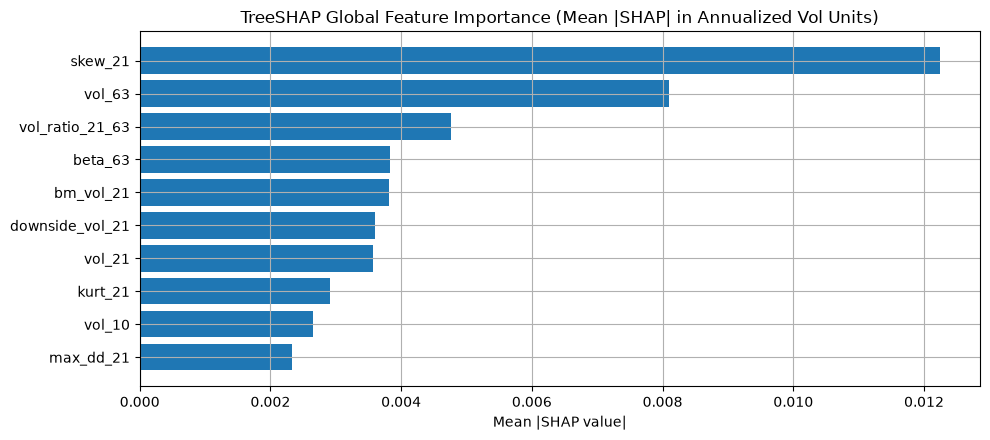

Local Explanation @ 2023-06-19 00:00:00: raw_pred=0.2619, base=0.2221, additivity_err=4.810e-08
  skew_21           : val=+0.7683 -> shap=+0.01836
  vol_63            : val=+0.2338 -> shap=+0.01171
  vol_ratio_21_63   : val=+1.0358 -> shap=+0.00666
  bm_vol_21         : val=+0.1756 -> shap=+0.00313
  vol_10            : val=+0.2545 -> shap=+0.00178
  kurt_21           : val=+0.7532 -> shap=-0.00145
Registry JSON round-trip verified (sha256=bf10c5dc63b33780...).


In [5]:
splitter = WalkForwardSplitter(mode='expanding', train_size=300, test_size=63, horizon_days=21)
last_fold = list(splitter.split(dataset.X, dataset.y))[-1]
X_tr = dataset.X.iloc[last_fold.train_indices.tolist()]
y_tr = dataset.y.iloc[last_fold.train_indices.tolist()]
X_te = dataset.X.iloc[last_fold.test_indices.tolist()]

tuned = TunedXGBoostVolatilityRegressor(horizon_days=21).fit(X_tr, y_tr)
fitted_xgb = tuned.fitted_regressor

global_shap = compute_global_shap(fitted_xgb, X_te, top_k=10)
check(global_shap.max_additivity_error <= 1e-4, 'SHAP additivity failed')
print(f'Selected params: {tuned.selected_params}')
print(f'Max SHAP additivity error (vs raw pred): {global_shap.max_additivity_error:.3e}')

# Plot Top-10 Global Feature Importance
top_names = [p[0] for p in reversed(global_shap.top_k_features)]
top_vals = [p[1] for p in reversed(global_shap.top_k_features)]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(top_names, top_vals)
ax.set_title('TreeSHAP Global Feature Importance (Mean |SHAP| in Annualized Vol Units)')
ax.set_xlabel('Mean |SHAP value|')
plt.tight_layout()
plt.show()

# Local explanation for highest-predicted volatility test date
raw_preds = fitted_xgb.predict(X_te)
peak_idx = int(np.argmax(raw_preds))
local_exp = explain_single_prediction(fitted_xgb, X_te, row_index=peak_idx, top_k=6)
print(f'Local Explanation @ {local_exp.timestamp}: raw_pred={local_exp.raw_prediction:.4f}, base={local_exp.base_value:.4f}, additivity_err={local_exp.additivity_error:.3e}')
for fname, sval in local_exp.top_contributors:
    print(f'  {fname:18s}: val={local_exp.feature_values[fname]:+.4f} -> shap={sval:+.5f}')

# Native XGBoost JSON persistence & SHA-256 verification
with tempfile.TemporaryDirectory() as tmpdir:
    reg = ModelRegistry(artifact_dir=tmpdir)
    manifest = fitted_xgb.save_to_registry(
        reg,
        model_id='xgb_vol_21d',
        version='v3.2.0',
        data_snapshot_hash=dataset.data_snapshot_hash,
        train_start_date=str(last_fold.train_start_date.date()),
        train_end_date=str(last_fold.train_end_date.date()),
    )
    reloaded, _ = XGBoostVolatilityRegressor.load_from_registry(reg, model_id='xgb_vol_21d', version='v3.2.0')
    np.testing.assert_allclose(raw_preds, reloaded.predict(X_te), rtol=1e-14)
    print(f'Registry JSON round-trip verified (sha256={manifest.artifact_sha256[:16]}...).')